# Stage 1 · What share rate is, and what to predict

Each section asks one question, answers it from the data, and ends with the decision it forces. The notebook reads
`data/snapshot.sqlite` (made by `scripts/export_snapshot.py`) and writes `data/stage1.sqlite`: the target and the
splits that stage 2 starts from. The numbers in the text are from the 11 October 2026 snapshot.

Nothing below prints a creator's name, caption or transcript. The notebook is meant to be published; the data is not.

In [1]:
import hashlib
import re
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SNAPSHOT = ROOT / "data" / "snapshot.sqlite"
STAGE1 = ROOT / "data" / "stage1.sqlite"

plt.rcParams.update({
    "figure.figsize": (8, 3.6),
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
snapshot = sqlite3.connect(SNAPSHOT)

## 1. What is in the data?

Only TikTok reports shares (YouTube's API returns none), so everything here is TikTok videos that have counts.
`fetched_at` is when the counts were read, so `age_days` is how old the video was at that moment.

In [2]:
videos = pd.read_sql(
    """SELECT username, video_id, published_at, fetched_at, duration_seconds,
              view_count AS views, share_count AS shares
       FROM videos
       WHERE platform = 'tiktok' AND has_stats = 1""",
    snapshot,
)
for column in ["published_at", "fetched_at"]:
    videos[column] = pd.to_datetime(videos[column], utc=True, format="ISO8601")
videos["age_days"] = (videos.fetched_at - videos.published_at).dt.total_seconds() / 86400

per_creator = videos.groupby("username").size()
print(f"{len(videos):,} videos from {videos.username.nunique()} creators")
print(f"Videos per creator: median {per_creator.median():.0f}, "
      f"10th percentile {per_creator.quantile(0.1):.0f}, 90th {per_creator.quantile(0.9):.0f}")
# Percentiles only: a min or a max would be one video's own counts.
videos[["views", "shares", "duration_seconds", "age_days"]].describe(percentiles=[0.1, 0.5, 0.9]).drop(
    ["min", "max"]).round(1)

156,484 videos from 246 creators
Videos per creator: median 376, 10th percentile 42, 90th 1702


,views,shares,duration_seconds,age_days
count,156484.0,156484.0,156484.0,156484.0
mean,1638768.0,7229.3,17.7,852.8
std,6843920.1,149984.9,14.1,706.3
10%,3379.0,4.0,6.0,83.0
50%,151600.0,264.0,12.0,668.7
90%,3500000.0,11500.0,41.0,1976.7


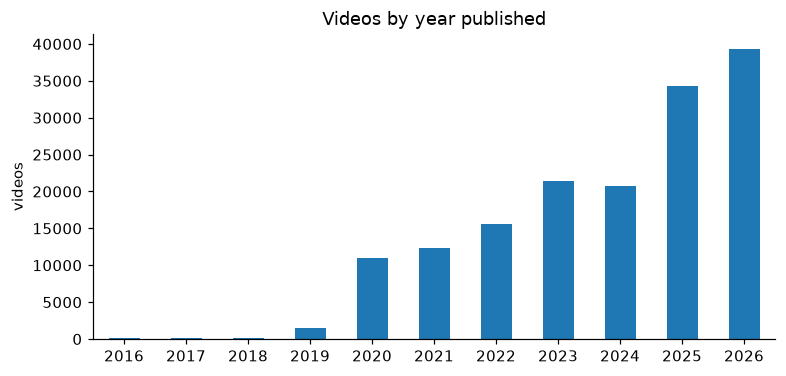

In [3]:
videos.published_at.dt.year.value_counts().sort_index().plot.bar(
    title="Videos by year published", xlabel="", ylabel="videos", rot=0)
plt.show()

**What it says.** About 156,000 videos from 246 creators. Views run from zero to hundreds of millions, so
everything below works on logarithms. Most videos were at least a year old when their counts were read (median age
about 670 days), and half were published in 2025 or 2026.

## 2. Share rate, and which videos are too small to measure

**Share rate** is shares per 1,000 views. Two choices make it measurable:

- **At least 1,000 views.** Below that, one share more or less moves the rate by a whole point (1 share in 500
  views is already 2 per 1,000). This drops under 4% of the videos.
- **Half a share added before taking the log.** About 4% of videos have zero shares, and the log of zero is
  undefined. `log10((shares + 0.5) / views × 1000)` gives them a finite value, and the half share stops mattering
  once a video has a few real ones.

150,719 of 156,484 videos have at least 1,000 views
Share rate percentiles (shares per 1,000 views):
0.10     0.21
0.25     0.56
0.50     1.79
0.75     5.92
0.90    15.46


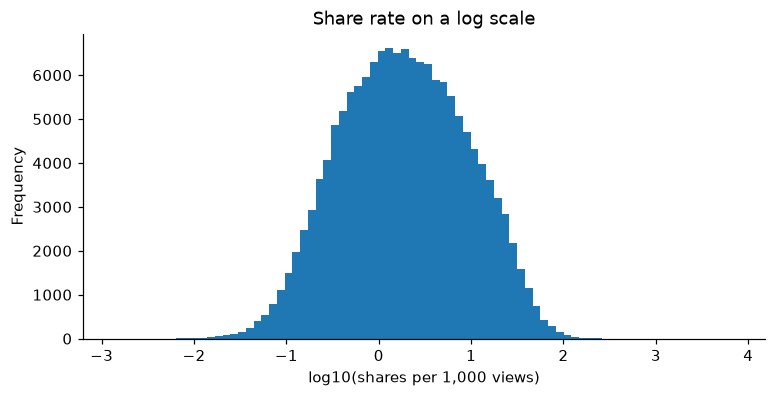

In [4]:
MIN_VIEWS = 1_000

measurable = videos[videos.views >= MIN_VIEWS].copy()
measurable["share_rate"] = measurable.shares / measurable.views * 1000
measurable["log_sr"] = np.log10((measurable.shares + 0.5) / measurable.views * 1000)

print(f"{len(measurable):,} of {len(videos):,} videos have at least {MIN_VIEWS:,} views")
print("Share rate percentiles (shares per 1,000 views):")
print(measurable.share_rate.quantile([0.1, 0.25, 0.5, 0.75, 0.9]).round(2).to_string())

measurable.log_sr.plot.hist(bins=80, title="Share rate on a log scale",
                            xlabel="log10(shares per 1,000 views)")
plt.show()

**What it says.** The median video gets about 1.8 shares per 1,000 views. The 90th percentile gets about 75 times
what the 10th does. On the log scale that becomes one broad hump, which is the shape a regression target should
have. On the raw scale a handful of viral videos would dominate every average.

## 3. How much of it is the creator, not the video?

If some creators are simply more shareable than others, a model fed raw share rate would mostly learn to
recognise creators. That is useless for the real question: *will this video do well for this creator?*

Knowing only the creator explains 38% of the variance in log share rate
Views vs share rate: r = -0.05 across all videos, r = 0.26 within each creator
The typical creator in the top decile gets 14.6 shares per 1,000 views, in the bottom decile 0.37: 40x apart (24 to 25 creators per decile)


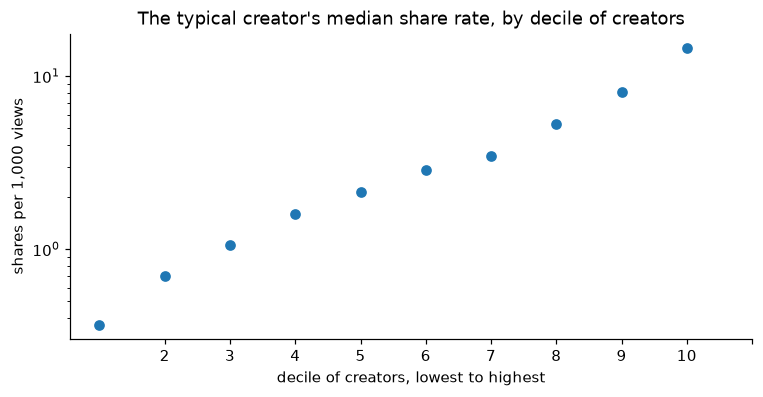

In [5]:
creator_mean = measurable.groupby("username").log_sr.transform("mean")
total = ((measurable.log_sr - measurable.log_sr.mean()) ** 2).sum()
within = ((measurable.log_sr - creator_mean) ** 2).sum()
print(f"Knowing only the creator explains {1 - within / total:.0%} of the variance in log share rate")

log_views = np.log10(measurable.views)
views_vs_rate = np.corrcoef(log_views, measurable.log_sr)[0, 1]
centred_views = log_views - log_views.groupby(measurable.username).transform("mean")
views_vs_rate_within = np.corrcoef(centred_views, measurable.log_sr - creator_mean)[0, 1]
print(f"Views vs share rate: r = {views_vs_rate:.2f} across all videos, "
      f"r = {views_vs_rate_within:.2f} within each creator")

# Deciles of creators, not one point per creator: every point on the chart covers at least 5 creators.
creator_medians = measurable.groupby("username").share_rate.median()
decile = pd.qcut(creator_medians.rank(method="first"), 10, labels=range(1, 11))
by_decile = creator_medians.groupby(decile, observed=True).agg(["median", "size"])
print(f"The typical creator in the top decile gets {by_decile['median'].iloc[-1]:.1f} shares per 1,000 views, "
      f"in the bottom decile {by_decile['median'].iloc[0]:.2f}: "
      f"{by_decile['median'].iloc[-1] / by_decile['median'].iloc[0]:.0f}x apart "
      f"({by_decile['size'].min()} to {by_decile['size'].max()} creators per decile)")
by_decile["median"].plot(marker="o", linestyle="", logy=True, xticks=range(1, 11),
                         title="The typical creator's median share rate, by decile of creators",
                         xlabel="decile of creators, lowest to highest", ylabel="shares per 1,000 views")
plt.show()

**What it says.** The creator alone explains about 38% of the variance, and creators' medians span two orders of
magnitude.

There's also a trap. Across all videos, views and share rate are unrelated (r ≈ −0.05). Within a creator they are
clearly related (r ≈ 0.26): the videos people share are the ones that travel further than that creator's usual.
Pooling creators hides the relation because big channels aren't more shareable than small ones. It's the same
mechanism as Simpson's paradox.

**Decisions.**
- Compare every video with its own creator.
- Views are an outcome, measured after posting, so never a feature. The same goes for likes, comments and saves.

## 4. Did share rate drift over time?

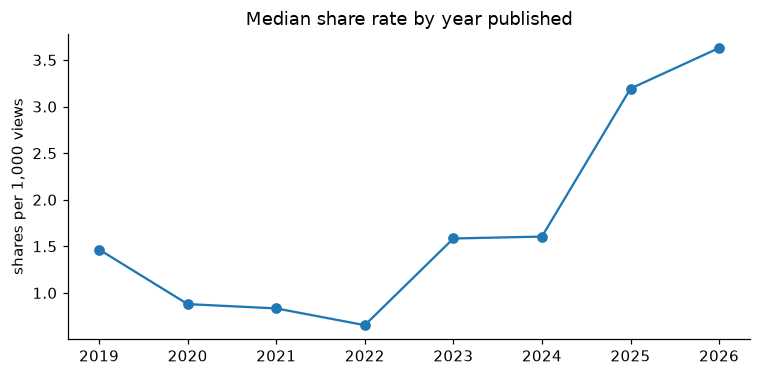

published_at
2019    1.47
2020    0.88
2021    0.83
2022    0.65
2023    1.58
2024    1.60
2025    3.19
2026    3.63


In [6]:
recent = measurable[measurable.published_at.dt.year >= 2019]
by_year = recent.groupby(recent.published_at.dt.year).share_rate.median()
by_year.plot(marker="o", title="Median share rate by year published", xlabel="",
             ylabel="shares per 1,000 views")
plt.show()
print(by_year.round(2).to_string())

A rise like this could come from the platform or from the library: maybe the creators downloaded for 2026 are
simply different from those for 2022. To tell the two apart, look only at creators who posted in both years and
compare each one with themselves.

In [7]:
years = measurable.published_at.dt.year
both = measurable[years.isin([2022, 2026])]
medians = both.groupby(["username", both.published_at.dt.year]).log_sr.median().unstack().dropna()
change = medians[2026] - medians[2022]
print(f"{len(medians)} creators posted in both 2022 and 2026")
print(f"Their own median share rate changed by {10 ** change.median():.1f}x (median), "
      f"and rose for {(change > 0).mean():.0%} of them")

113 creators posted in both 2022 and 2026
Their own median share rate changed by 4.7x (median), and rose for 96% of them


**What it says.** The median rose from about 0.65 shares per 1,000 views for 2022 videos to about 3.6 for 2026.
The same creators show it: roughly 4.7× for the median creator, with almost every creator rising. So it's the
platform, not the library's mix. The data can't say whether the cause is how TikTok counts shares or how it offers
the share button, and it doesn't need to.

**Decisions.**
- A video is compared with its creator's **recent** videos, not their lifetime average. Otherwise every 2026 video
  would look like a breakout against the creator's 2021 self.
- Split by time, so the test set holds the newest videos, as it would in real use.

## 5. Are young videos still moving?

Counts were read once per video, at different ages. A video read two days after posting hasn't finished
collecting views. The question is whether its **rate** is still moving. The `snapshots` table answers it: about
30,000 videos were measured again at least a week later.

In [8]:
snaps = pd.read_sql(
    """SELECT s.username, s.video_id, s.captured_at, s.view_count AS views,
              s.share_count AS shares, v.published_at
       FROM snapshots s JOIN videos v USING (platform, username, video_id)
       WHERE s.platform = 'tiktok'""",
    snapshot,
)
for column in ["captured_at", "published_at"]:
    snaps[column] = pd.to_datetime(snaps[column], utc=True, format="ISO8601")
snaps = snaps.sort_values("captured_at")

per_video = snaps.groupby(["username", "video_id"])
first, last = per_video.first(), per_video.last()
moves = pd.DataFrame({
    "measurements": per_video.size(),
    "age_at_first": (first.captured_at - first.published_at).dt.days,
    "days_between": (last.captured_at - first.captured_at).dt.days,
    "rate_first": first.shares / first.views * 1000,
    "rate_last": last.shares / last.views * 1000,
    "view_growth": last.views / first.views,
})
moves = moves[(moves.measurements >= 2) & (moves.days_between >= 7) & (first.views >= MIN_VIEWS)]
moves["rate_change"] = (moves.rate_last + 0.01) / (moves.rate_first + 0.01)
moves["age_band"] = pd.cut(moves.age_at_first, [-1, 3, 7, 14, 30, 90, 365, 10_000],
                           labels=["0-3", "4-7", "8-14", "15-30", "31-90", "91-365", "over 365"])

print(f"{len(moves):,} videos measured twice, a median {moves.days_between.median():.0f} days apart")
print(f"Rank correlation of share rate between the two measurements: "
      f"{moves[['rate_first', 'rate_last']].corr(method='spearman').iloc[0, 1]:.3f}")
moves.reset_index().groupby("age_band", observed=True).agg(
    videos=("view_growth", "size"),
    creators=("username", "nunique"),
    median_view_growth=("view_growth", "median"),
    median_rate_change=("rate_change", "median"),
    moved_over_20pct=("rate_change", lambda change: ((change > 1.2) | (change < 1 / 1.2)).mean()),
).round(3)

30,093 videos measured twice, a median 60 days apart
Rank correlation of share rate between the two measurements: 0.999


,videos,creators,median_view_growth,median_rate_change,moved_over_20pct
age_band,,,,,
0-3,177,25,1.632,0.926,0.282
4-7,213,37,1.303,0.948,0.211
8-14,411,49,1.213,0.961,0.127
15-30,932,64,1.134,0.984,0.104
31-90,3034,71,1.027,0.996,0.024
91-365,9404,76,1.002,0.999,0.007
over 365,15922,63,1.000,1.000,0.001


**What it says.** Videos read in their first three days kept growing (views ×1.6 at the median), but their share
rate barely moved: it dropped about 7%, and the ranking of videos by share rate is almost identical between the two
readings. After two weeks the rate is settled. Shares and views grow together, so the ratio holds still while the
counts don't. That is one more reason to predict the rate and not a count.

**Decision.** Keep videos that were at least 14 days old when read. That drops about 1% of them.

## 6. Survivorship: which clips still have their file?

The platform retires old clips to save disk space but keeps each channel's top clips by share rate. If that's
right, whether a clip still has its file depends on the target, and anything built from that fact leaks.

In [9]:
files = pd.read_sql(
    "SELECT username, video_id, has_video, retire_reason FROM files WHERE platform = 'tiktok'", snapshot)
kept = measurable.merge(files, on=["username", "video_id"])
kept["vs_creator_median"] = kept.log_sr - kept.groupby("username").log_sr.transform("median")

survivors = kept.groupby("has_video").agg(
    videos=("log_sr", "size"),
    above_creator_median=("vs_creator_median", lambda x: (x > 0).mean()),
)
survivors.index = survivors.index.map({0: "file retired", 1: "file still on disk"})
print(kept.retire_reason.fillna("(not retired)").value_counts().to_string())
survivors.round(3)

retire_reason
below-top        102253
(not retired)     48466


,videos,above_creator_median
has_video,,
file retired,101962,0.433
file still on disk,48757,0.638


**What it says.** Clips that still have their file sit above their creator's median 55% of the time; retired clips
only 43% of the time. The retirement reason is "below-top" for every retired clip. The leak is real.

**Decisions.**
- `has_video`, `retired_at` and `retire_reason` are never features.
- Never train only on clips that still have their file: that sample is tilted toward winners.
- In stage 4 every video's image must come out of **one** pipeline. Retired clips have only a poster, taken by
  PyAV about 1 second in, scaled to 480 px on the long edge and saved as JPEG quality 82. Frames from the kept clips
  must be made exactly the same way. Otherwise the model can learn to spot compression artefacts, which here would
  mean spotting "retired", which here means "below the creator's top". A suspiciously good image model is the
  warning sign.

## 7. Videos with no counts

About 91,000 TikTok videos have notes and pixels but no counts. They can't have a target, so this stage leaves them
out. The question is whether leaving them out biases what's left.

In [10]:
runs = pd.read_sql(
    "SELECT username, videos_seen, error FROM stat_runs WHERE platform = 'tiktok'", snapshot)
missing = pd.read_sql(
    "SELECT username, COUNT(*) AS videos FROM videos "
    "WHERE platform = 'tiktok' AND has_stats = 0 GROUP BY username",
    snapshot,
).merge(runs, on="username", how="left")

counted_creators = set(videos.username)
has_some_counts = missing.username.isin(counted_creators)
missing["why"] = np.select(
    [missing.videos_seen.isna(),
     (missing.videos_seen == 0) & ~has_some_counts,
     (missing.videos_seen == 0) & has_some_counts,
     has_some_counts],
    ["never fetched (no counts at all)",
     "fetch returned nothing (no counts at all)",
     "last fetch returned nothing, an earlier one worked",
     "fetch returned part of the channel"],
    default="fetch returned videos, none matched",
)
missing.groupby("why").agg(creators=("username", "size"), videos=("videos", "sum"))

,creators,videos
why,,
fetch returned nothing (no counts at all),41,33789
fetch returned part of the channel,48,16096
"last fetch returned nothing, an earlier one worked",66,13631
never fetched (no counts at all),33,27373


**What it says.** About two in three of the missing videos belong to creators with no counts at all: the fetch
never ran, or it ran and returned nothing. For 66 more creators an earlier fetch worked but the last one returned
nothing. Both are collection failures, not something about how the videos did, so dropping them shrinks the data
without tilting the per-creator target. The creators fetched only in part are less innocent. A video can be
missing because its creator deleted it, and people delete what flopped. They are about one in six of the missing
videos and a small share of the whole. Re-export once the counts are fetched again, and check whether the numbers
here move.

**Decision.** Train and test only on videos with counts. Treat any result as holding for creators like these 234.

## 8. The target

For each measurable video at least 14 days old:

- **Baseline:** the median `log_sr` of the same creator's previous 30 measurable videos, by publish date. It needs
  at least 10 of them, so each creator's first 10 videos get no target.
  - **Previous only** (`shift(1)`): the video itself must never be part of its own baseline, or the target leaks
    into it.
  - **The median, not the mean,** because share rate is fat-tailed: one viral video would drag a mean for 30 videos.
  - **The last 30, not all of them,** because of the drift in section 4.
- **`lift = log_sr − baseline`**, in log10 units: 0 means a typical video for this creator right now, +0.3 means
  twice the creator's recent median, −0.3 means half.
- **`breakout = lift ≥ log10(2)`**: at least twice the creator's recent median. This is the yes/no version of the
  same target, for when a ranking or a hit rate is easier to explain than an error.

143,489 videos from 231 creators have a target
lift: median +0.008, standard deviation 0.489 (log10 units)
breakout rate: 24.5%

Stage 1 had a target for 146,431 videos; 2,942 lose it, having fewer than 10 videos posted at least 14 days earlier
Correlation of the two baselines: 0.963
Breakout labels that flip: 6.77%


R2_of_log_sr        error_of_predicting_zero        breakout_rate  \
baseline        stage 1  as-of                  stage 1  as-of       stage 1   
split                                                                          
train             0.509  0.476                    0.359  0.371         0.236   
validation        0.468  0.444                    0.363  0.371         0.235   
test              0.363  0.332                    0.366  0.376         0.236   

                   
baseline    as-of  
split              
train       0.245  
validation  0.242  
test        0.247

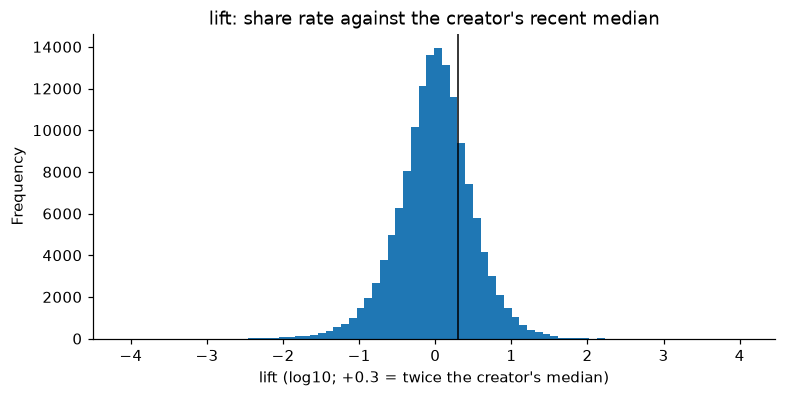

In [11]:
WINDOW, MIN_PRIOR, MIN_AGE_DAYS = 30, 10, 14
SETTLED = np.timedelta64(MIN_AGE_DAYS, "D")
LOG2 = np.log10(2)

# The pool a baseline draws from: measurable videos that were at least 14 days old when read.
pool = measurable[measurable.age_days >= MIN_AGE_DAYS].sort_values(
    ["username", "published_at", "video_id"]).copy()


def as_of_baseline(creator):
    """For each of one creator's videos (sorted by publish date), the median log_sr of the last 30 of their
    pool videos posted at least 14 days before it, so each of those rates had settled by then."""
    posted = creator.published_at.dt.tz_localize(None).to_numpy()
    rates = creator.log_sr.to_numpy()
    ends = np.searchsorted(posted, posted - SETTLED, side="right")  # rows [0, end) were posted <= t - 14 days
    starts = np.maximum(ends - WINDOW, 0)
    return pd.DataFrame({
        "baseline": [np.median(rates[s:e]) if e - s >= MIN_PRIOR else np.nan for s, e in zip(starts, ends)],
        "n_prior": ends - starts,
    }, index=creator.index)


pool = pool.join(pool.groupby("username", group_keys=False)[["published_at", "log_sr"]].apply(as_of_baseline))
# Stage 1's baseline, kept only for the comparison below: the previous 30 pool videos, however recent.
pool["stage1_baseline"] = pool.groupby("username").log_sr.transform(
    lambda rates: rates.shift(1).rolling(WINDOW, min_periods=MIN_PRIOR).median())

target = pool.dropna(subset=["baseline"]).drop(columns="stage1_baseline")
target["lift"] = target.log_sr - target.baseline
target["breakout"] = (target.lift >= LOG2).astype(int)

print(f"{len(target):,} videos from {target.username.nunique()} creators have a target")
print(f"lift: median {target.lift.median():+.3f}, standard deviation {target.lift.std():.3f} (log10 units)")
print(f"breakout rate: {target.breakout.mean():.1%}")

# The fix, side by side with stage 1, on the rows both baselines cover and stage 1's split dates (section 9).
CUT_VALIDATION = pd.Timestamp("2025-10-10T11:24:43Z")
CUT_TEST = pd.Timestamp("2026-04-01T03:40:54.5Z")
both = pool.dropna(subset=["baseline", "stage1_baseline"])
period = pd.Series(np.select([both.published_at < CUT_VALIDATION, both.published_at < CUT_TEST],
                             ["train", "validation"], default="test"), index=both.index)


def r2(y, prediction):
    return 1 - ((y - prediction) ** 2).sum() / ((y - y.mean()) ** 2).sum()


print(f"\nStage 1 had a target for {pool.stage1_baseline.notna().sum():,} videos; "
      f"{pool.stage1_baseline.notna().sum() - len(both):,} lose it, having fewer than {MIN_PRIOR} videos "
      f"posted at least {MIN_AGE_DAYS} days earlier")
print(f"Correlation of the two baselines: {np.corrcoef(both.baseline, both.stage1_baseline)[0, 1]:.3f}")
stage1_breakout = both.log_sr - both.stage1_baseline >= LOG2
asof_breakout = both.log_sr - both.baseline >= LOG2
print(f"Breakout labels that flip: {(stage1_breakout != asof_breakout).mean():.2%}")
comparison = pd.DataFrame([
    {"split": split, "baseline": name,
     "R2_of_log_sr": r2(rows.log_sr, rows[column]),
     "error_of_predicting_zero": (rows.log_sr - rows[column]).abs().mean(),
     "breakout_rate": (rows.log_sr - rows[column] >= LOG2).mean()}
    for split, rows in both.groupby(period)
    for name, column in [("stage 1", "stage1_baseline"), ("as-of", "baseline")]
]).pivot(index="split", columns="baseline")
display(comparison.reindex(index=["train", "validation", "test"], columns=["stage 1", "as-of"], level=1).round(3))

target.lift.plot.hist(bins=80, title="lift: share rate against the creator's recent median",
                      xlabel="lift (log10; +0.3 = twice the creator's median)")
plt.axvline(LOG2, color="black", linewidth=1)
plt.show()

**What it says.** About 146,000 videos from 234 creators get a target. The creator's recent history alone explains
about half the variance in log share rate, against 38% for the creator's lifetime mean in section 3. Recency
matters. About 24% of videos are breakouts.

That half is the bar. Stage 2's first model is "every video does as well as its creator's recent median", which
means predicting `lift = 0`. Every later model has to explain part of the other half.

## 9. The splits

- **By time:** train on the oldest 70% of videos by publish date, validate on the next 15%, test on the newest
  15%. A random split would put a creator's near-identical videos on both sides, and future videos into training.
- **By creator:** about one creator in five is held out entirely, to answer "does this work for a creator the
  model has never seen?" The choice is `md5(username) mod 5 == 0` rather than a random draw, so a creator keeps
  their group when the snapshot is re-exported with new creators in it.

In [12]:
# Frozen on the 2026-10-14 snapshot: stage 1's cut instants (cell 27), not quantiles re-computed on new rows.
# Counts that arrive in a later export never enter these splits, so the notebook refuses to run on one.
FROZEN_SNAPSHOT = "2026-10-14T09:56:20+00:00"
exported_at = snapshot.execute("SELECT value FROM export_info WHERE key = 'exported_at'").fetchone()[0]
assert exported_at == FROZEN_SNAPSHOT, f"The splits are frozen on the {FROZEN_SNAPSHOT} export, not {exported_at}"

target["time_split"] = np.select(
    [target.published_at < CUT_VALIDATION, target.published_at < CUT_TEST],
    ["train", "validation"],
    default="test",
)
target["creator_group"] = [
    "holdout" if int(hashlib.md5(name.encode()).hexdigest(), 16) % 5 == 0 else "train"
    for name in target.username
]
# Rule 3: a training-group creator counts as seen only if they have videos in the training period.
training = (target.time_split == "train") & (target.creator_group == "train")
target["creator_seen"] = np.select(
    [target.creator_group == "holdout", target.username.isin(target.username[training])],
    ["holdout", "seen"],
    default="new",
)

# Reposts: an evaluation video whose clip (same English transcript of at least 8 words, same on-screen text,
# same duration) is also among the training rows. Stages 3 and 4 report with and without them.
texts = pd.read_sql(
    """SELECT username, video_id, transcript_en, onscreen_text_en, duration_seconds
       FROM videos WHERE platform = 'tiktok' AND has_stats = 1""",
    snapshot,
)


def normalised(text):
    text = re.sub(r"[^\w\s]", " ", text.lower() if isinstance(text, str) else "")
    return " ".join(text.split())


transcript = texts.transcript_en.map(normalised)
texts["clip_key"] = [
    hashlib.sha1(f"{words}|{normalised(onscreen)}|{duration}".encode()).hexdigest()
    if len(words.split()) >= 8 else None
    for words, onscreen, duration in zip(transcript, texts.onscreen_text_en, texts.duration_seconds)
]
clips = target[["username", "video_id"]].merge(texts, on=["username", "video_id"], how="left").clip_key
clips.index = target.index
target["has_twin"] = ((target.time_split != "train") & clips.isin(clips[training].dropna())).astype(int)

print(f"Validation from {CUT_VALIDATION:%Y-%m-%d %H:%M}, test from {CUT_TEST:%Y-%m-%d %H:%M} (UTC)")
print(target.groupby("creator_group").username.nunique().rename("creators").to_string(), "\n")
groups = target.groupby(["time_split", "creator_seen"]).agg(
    creators=("username", "nunique"), videos=("lift", "size"), twins=("has_twin", "sum"))
display(groups.unstack().reindex(["train", "validation", "test"])
        .reindex(columns=["seen", "new", "holdout"], level=1).fillna(0).astype(int))
summary = target.groupby("time_split").agg(
    videos=("lift", "size"),
    mean_lift=("lift", "mean"),
    breakout_rate=("breakout", "mean"),
    error_of_predicting_zero=("lift", lambda x: x.abs().mean()),
).loc[["train", "validation", "test"]]
summary.round(3)

Validation from 2025-10-10 11:24, test from 2026-04-01 03:40 (UTC)
creator_group
holdout     43
train      188 



creators             videos               twins            
creator_seen     seen new holdout   seen   new holdout  seen new holdout
time_split                                                              
train             148   0      35  74552     0   25865     0   0       0
validation        138  27      38  13646  2275    5411    73   3      18
test              138  39      42  12455  4901    4384    46  12      10

,videos,mean_lift,breakout_rate,error_of_predicting_zero
time_split,,,,
train,100417,-0.002,0.245,0.371
validation,21332,-0.009,0.242,0.371
test,21740,-0.009,0.247,0.376


**What it says.** The target looks the same in every split: mean lift near zero, about 24% breakouts each time.
The rolling baseline has absorbed the drift that made raw share rate rise fivefold. A model trained on 2024 can be
tested on 2026 without the target changing under it. The last column is the stage 2 bar written as an error: on
the test set, "predict zero" misses by about 0.37 log10 units on average, roughly a factor of 2.3.

## 10. Save what stage 2 starts from

Identifiers, dates, the target and the splits. No `files` columns, and no counts other than the two the target is
built from.

In [13]:
columns = ["username", "video_id", "published_at", "age_days", "views", "shares", "share_rate", "log_sr",
           "n_prior", "baseline", "lift", "breakout", "time_split", "creator_group",
           "creator_seen", "has_twin"]
targets = target[columns].copy()
targets["published_at"] = targets.published_at.dt.strftime("%Y-%m-%dT%H:%M:%S%z")

out = sqlite3.connect(STAGE1)
targets.to_sql("targets", out, if_exists="replace", index=False)
out.execute("CREATE UNIQUE INDEX IF NOT EXISTS targets_key ON targets (username, video_id)")
out.commit()
out.close()
print(f"Wrote {len(targets):,} rows to {STAGE1.relative_to(ROOT)}")

Wrote 143,489 rows to data\stage1.sqlite


## What stage 1 decided

| Question | Answer | Decision |
|---|---|---|
| What to measure | Shares per 1,000 views, spread about 75× between the 10th and 90th percentile | Work on `log10((shares + 0.5) / views × 1000)`; only videos with at least 1,000 views |
| Creator or video? | The creator explains about 38% of the variance | Compare each video with its own creator |
| Drift | The same creators' share rate rose about 4.7× from 2022 to 2026 | Baseline = the median of the creator's previous 30 videos; split by time |
| Young videos | Views still grow, the rate barely moves | Keep videos at least 14 days old |
| Survivorship | Kept clips beat their creator's median 55% of the time, retired ones 43% | File columns are never features; one image pipeline for every video in stage 4 |
| Missing counts | Two in three missing videos are whole creators the fetch missed | Use videos with counts; re-export after a re-fetch |
| Target | 146k videos, 234 creators; the baseline explains about 52% | `lift` (regression) and `breakout` (lift ≥ 2×, about 24%) |
| Splits | The target's distribution is the same in every split | 70/15/15 by publish date; one creator in five held out |